First 5 rows:
    Loan_ID  Gender Married Dependents     Education Self_Employed  \
0  LP002314  Female      No          0  Not Graduate            No   
1  LP002315    Male     Yes          1      Graduate            No   
2  LP002317    Male     Yes         3+      Graduate            No   
3  LP002318  Female      No          1  Not Graduate           Yes   
4  LP002319    Male     Yes          0      Graduate           NaN   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             2213                0.0        66.0             360.0   
1             8300                0.0       152.0             300.0   
2            81000                0.0       360.0             360.0   
3             3867                0.0        62.0             360.0   
4             6256                0.0       160.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Rural           Y  
1             0.0     Semiurban           N  


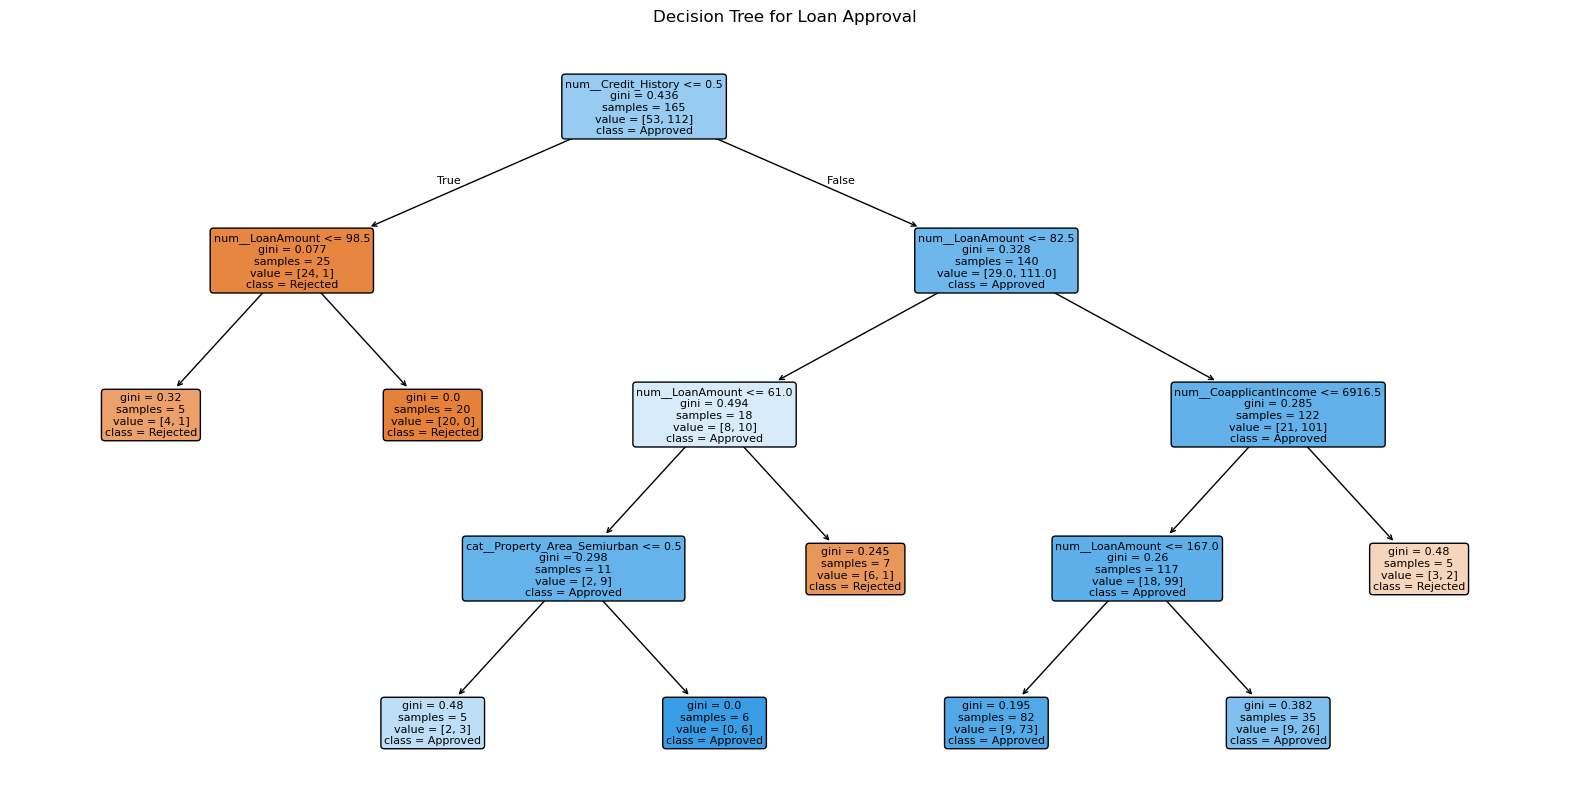

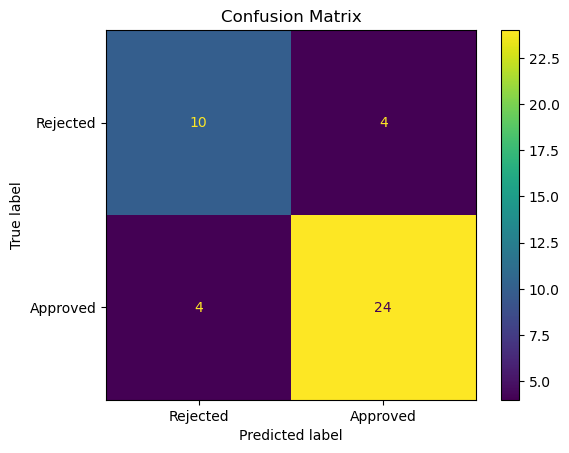

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# 1. Load the dataset
df = pd.read_excel("loan.xlsx")

print("First 5 rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

# 2. Clean the Dependents column
df["Dependents"] = pd.to_numeric(
    df["Dependents"].astype(str).str.replace("+", "", regex=False),
    errors="coerce"
)

# 3. Separate features and target
X = df.drop(columns=["Loan_ID", "Loan_Status"])
y = df["Loan_Status"].map({"N": 0, "Y": 1})

# 4. Identify numerical and categorical columns
numeric_cols = [
    "Dependents", "ApplicantIncome", "CoapplicantIncome",
    "LoanAmount", "Loan_Amount_Term", "Credit_History"
]

categorical_cols = [
    "Gender", "Married", "Education",
    "Self_Employed", "Property_Area"
]

# 5. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 6. Handle missing values and encode categories
num_transformer = SimpleImputer(strategy="median")

cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", num_transformer, numeric_cols),
    ("cat", cat_transformer, categorical_cols)
])

# 7. Create the Decision Tree classifier
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        min_samples_leaf=5,
        random_state=42
    ))
])

# 8. Train the model
model.fit(X_train, y_train)

# 9. Predict loan approval
y_pred = model.predict(X_test)

# 10. Evaluate the model
print("\nModel Performance:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

# 11. Compare actual and predicted loan status
results = pd.DataFrame({
    "Actual": y_test.map({0: "Rejected", 1: "Approved"}).values,
    "Predicted": pd.Series(y_pred).map(
        {0: "Rejected", 1: "Approved"}
    ).values
})

print("\nActual vs Predicted:")
print(results.head(10))

# 12. Visualize the Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    model.named_steps["classifier"],
    feature_names=model.named_steps[
        "preprocessor"
    ].get_feature_names_out(),
    class_names=["Rejected", "Approved"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree for Loan Approval")
plt.show()

# 13. Visualize the Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"]
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()
